# Symmetry Breaking of Azimuthal Thermoacoustic Modes: the UQ Perspective

__Michael Bauerheim__, CERFACS, CFD team, Toulouse, France

__Aïssatou Ndiaye__, CERFACS, CFD team, Toulouse, France

__Paul Constantine__, Colorado School of Mines, USA

__Stéphane Moreau__, Sherbrooke University, Canada

__Franck Nicoud__, Université Montpellier 2, I3M UMR CNRS 5149, France

The model written as a nonlinear eigenproblem, with adjoint sensitivities: __Luca Magri__ (Center for Turbulence Research, Stanford University; Cambridge University Engineering Department), __Michael Bauerheim__ (CAPS Lab, ETH Zürich), __Matthew P. Juniper__ (Cambridge University Engineering Department).

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import active_subspaces as ac
import annular_combustor_model as acm
import generate_data as gd

SEED = 2016                       # the only seed in this notebook (bootstrap, fresh samples)
t_start = time.perf_counter()
N, CASES = acm.N, ('weak', 'strong')
labels = [f'$n_{{{i}}}$' for i in range(1, N + 1)] + [rf'$\tau_{{{i}}}$' for i in range(1, N + 1)]

### Summary

Bauerheim et al. [[1]](https://doi.org/10.1017/jfm.2015.730) model the first azimuthal thermoacoustic mode of an annular combustion chamber fed by 19 burners from a common annular plenum with the ATACAMAC network model, whose complex eigenfrequency solves a nonlinear dispersion relation, and they treat the gain $n_i$ and time delay $\tau_i$ of each burner's flame as uncertain, 38 inputs in all, in a weakly and a strongly coupled operating point. This notebook uses a new numpy implementation of that dispersion relation (`annular_combustor_model.py`) with exact gradients of the growth rate from the implicit function theorem, and finds the paper's structure: five (weak case) or six (strong case) eigenvalues above 1 % of the largest in the original coordinates, a first eigenvector that weights the 19 time delays (weak case) or gains and delays (strong case) equally, and second and third eigenvectors with azimuthal period $N/2$, which a change of variables to the spatial Fourier coefficients $\hat F(k)$ of $F_i = n_i e^{j\omega^0\tau_i}$ reduces to $\hat F(0)$ and $\hat F(\pm 2)$. In the weak case the model reproduces the paper's Monte Carlo risk factor (15.33 % against 14.77 %), its surrogate accuracies and surrogate risk factors, and the 2016 data to $1.5\times10^{-3}$ s$^{-1}$; in the strong case the risk factor of the larger of the two growth rates is 66.49 %, not the paper's 39.55 %, and the evidence (below and in `DATA.md`) is that the paper's strong-case values are the growth rate of whichever of the two split components its root finder reached, not the larger one.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by Monte Carlo from gradient samples and use the bootstrap to judge the eigenvalues and subspaces. See P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015 ([doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)).

### The model

**Geometry and acoustics** ([[1]](https://doi.org/10.1017/jfm.2015.730) §2, Fig. 3). An annular plenum (half-perimeter $L_p$, section $S_p$, fresh gas $\rho_u, c_u$) feeds $N = 19$ burners (length $L_i$, section $S_i$) that open into an annular chamber ($L_c$, $S_c$, burnt gas $\rho^0, c^0$). Perturbations are $a'(\mathbf x, t) = \hat a(\mathbf x)e^{-j\omega t}$, so **$\mathrm{Im}(\omega) > 0$ is a growing, unstable mode** ([[1]](https://doi.org/10.1017/jfm.2015.730) p. 5). The state at one azimuthal position is $X = [\hat p_p, -j\rho_u c_u\hat u_p, \hat p_c, -j\rho^0 c^0\hat u_c]^T$ ([[2]](https://doi.org/10.1016/j.jcp.2016.07.032) eq. 35). Over one sector, acoustics propagates by the rotation matrix (eq. 2.2) $R = \mathrm{diag}\big(R(k_u\,2L_p/N), R(k\,2L_c/N)\big)$, $R(x) = \begin{bmatrix}\cos x & -\sin x\\ \sin x & \cos x\end{bmatrix}$, $k = \omega/c^0$, $k_u = \omega/c_u$, and burner $i$ couples the two cavities through (eq. 2.3)

$$T_i = I + 2\begin{bmatrix}0&0&0&0\\ \Gamma_{i,1}&0&\Gamma_{i,2}&0\\ 0&0&0&0\\ \Gamma_{i,3}&0&\Gamma_{i,4}&0\end{bmatrix},\qquad
\Gamma_{i,1} = -\frac{S_i}{2S_p}\frac{C c - \mathbb F_i S s}{\Delta_i},\
\Gamma_{i,2} = \frac{S_i}{2S_p}\frac{1}{\Delta_i},\
\Gamma_{i,3} = \frac{S_i}{2S_c}\frac{\mathbb F_i}{\Delta_i},\
\Gamma_{i,4} = -\frac{S_i}{2S_c}\frac{\mathbb F_i C c - S s}{\Delta_i},$$

with $C, S = \cos, \sin(k(1-\alpha)L_i)$, $c, s = \cos, \sin(k_u\alpha L_i)$, $\Delta_i = C s + \mathbb F_i S c$ (eqs. 2.4–2.7), the flame at $z = \alpha L_i$ in the burner, and the $n$–$\tau$ flame model (eqs. 2.1, 2.8)

$$\mathbb F_i = \frac{\rho^0 c^0}{\rho_u c_u}\left(1 + n_i e^{j\omega\tau_i}\right).$$

**Dispersion relation** (eq. 2.11; [[2]](https://doi.org/10.1016/j.jcp.2016.07.032) eq. 30): $D(\omega) = \det\left(R T_N \cdots R T_2\, R T_1 - I\right) = 0$.

**Quantity of interest.** In the symmetric configuration ($n_i = \bar n$, $\tau_i = \bar\tau$) the first azimuthal mode is a double root of $D$; unequal burners split it into two roots $\omega_1, \omega_2$. The QoI is the larger growth rate, $f_{Im} = \max(\mathrm{Im}\,\omega_1, \mathrm{Im}\,\omega_2)/(2\pi)$ in s$^{-1}$ ([[1]](https://doi.org/10.1017/jfm.2015.730) §4.2 and App. A.1), and the **risk factor** is $P(f_{Im} > 0)$ (eq. 3.2).

**Solver** (`annular_combustor_model.py`). The symmetric root is found from the Bloch condition $\det(RT - e^{2\pi j/N}I) = 0$ by the secant method from $\omega^0 = \pi c^0/L_c$. For each sample, the contour integrals $\frac{1}{2\pi j}\oint z^k D'/D\,d\omega$, $k = 0, 1, 2$, on a circle of radius 300 rad/s (weak) or 450 rad/s (strong) around the symmetric root give the number of roots inside (it must be 2: this is the check that we follow the right branch) and the two roots, which are then polished by Newton steps on $D/(\omega - \omega_{\rm other})$. $D'$ is analytic. **Gradients** are exact, by the implicit function theorem: $\partial\omega/\partial p = -(\mathbf y^H \partial_p A\,\mathbf x)/(\mathbf y^H \partial_\omega A\,\mathbf x)$ with $A = M - I$ and $\mathbf x$, $\mathbf y$ its right and left null vectors (the adjoint formula of [[2]](https://doi.org/10.1016/j.jcp.2016.07.032)), and $\nabla f_{Im} = \mathrm{Im}(\nabla\omega)/(2\pi)$ of the component that attains the maximum.

**Constants and inputs.** The constants are those of [[1]](https://doi.org/10.1017/jfm.2015.730) Table 1, except two: [[1]](https://doi.org/10.1017/jfm.2015.730) does not give the flame position $\alpha$, and its burner length ($L_i^0 = 0.04$ m) differs from that of [[2]](https://doi.org/10.1016/j.jcp.2016.07.032) Table 1 ($L_i = 0.0551$ m, $\alpha = 0.862$), which states "same parameters as" [[1]](https://doi.org/10.1017/jfm.2015.730). We use [[2]](https://doi.org/10.1016/j.jcp.2016.07.032)'s values: with them the model reproduces [[2]](https://doi.org/10.1016/j.jcp.2016.07.032) Table 2 (below) and the 2016 weak-case data to $1.5\times10^{-3}$ s$^{-1}$ (`DATA.md`). The inputs are independent and uniform with standard deviations 10 % ($n_i$) and 5 % ($\tau_i$) of the mean ([[1]](https://doi.org/10.1017/jfm.2015.730) p. 13 and Table 2; the same design as the companion study [3], p. 213), so the half-widths are $\sqrt 3$ times these. The table below is printed from the code.

In [2]:
print('Constants (JFM Table 1; L_i and alpha from Magri et al. Table 1):')
for name, val, unit in [('L_c', acm.L_C, 'm'), ('L_p', acm.L_P, 'm'), ('S_c', acm.S_C, 'm^2'),
                        ('S_p', acm.S_P, 'm^2'), ('S_i', acm.S_I, 'm^2'), ('L_i', acm.L_I, 'm'),
                        ('alpha', acm.ALPHA, '-'), ('rho_u', acm.RHO_U, 'kg/m^3'), ('c_u', acm.C_U, 'm/s'),
                        ('rho_0', acm.RHO_B, 'kg/m^3'), ('c_0', acm.C_B, 'm/s')]:
    print(f'  {name:6s} {val:>9g} {unit}')
print(f'\n{"case":7s}{"input":10s}{"nominal":>11s}{"lower":>13s}{"upper":>13s}{"sd":>11s}  distribution')
for c in CASES:
    lo, up = acm.bounds(c)
    for j, nm in ((0, 'n_i'), (N, 'tau_i [s]')):
        print(f'{c:7s}{nm:10s}{(lo[j] + up[j]) / 2:11.4g}{lo[j]:13.6g}{up[j]:13.6g}'
              f'{(up[j] - lo[j]) / np.sqrt(12):11.4g}  uniform, i = 1..19, independent')
print()
for c in CASES:
    w = acm.symmetric_root(c)
    print(f'{c}: symmetric root omega = {w.real:.2f} {w.imag:+.3f}j rad/s, '
          f'f = {w.real / 2 / np.pi:.2f} Hz, Im f = {w.imag / 2 / np.pi:+.3f} 1/s')
wA, wB = acm.symmetric_root((0.5, 6.223e-4)), acm.symmetric_root((1.75, 7.35e-4))
print(f'Magri et al. Table 2: case A omega = {wA.real:.1f} {wA.imag:+.3f}j (paper 5.059e3 - 1.392j); '
      f'case B omega = {wB.real:.1f} {wB.imag:+.3f}j (paper 4.272e3 + 3.600e-3j)')

Constants (JFM Table 1; L_i and alpha from Magri et al. Table 1):
  L_c         0.54 m
  L_p         0.54 m
  S_c      0.00785 m^2
  S_p      0.00785 m^2
  S_i      0.00028 m^2
  L_i       0.0551 m
  alpha      0.862 -
  rho_u      10.93 kg/m^3
  c_u          519 m/s
  rho_0        4.7 kg/m^3
  c_0          832 m/s

case   input         nominal        lower        upper         sd  distribution
weak   n_i               0.5     0.413397     0.586603       0.05  uniform, i = 1..19, independent
weak   tau_i [s]    0.000635  0.000580007  0.000689993  3.175e-05  uniform, i = 1..19, independent
strong n_i              1.75      1.44689      2.05311      0.175  uniform, i = 1..19, independent
strong tau_i [s]    0.000735  0.000671347  0.000798653  3.675e-05  uniform, i = 1..19, independent

weak: symmetric root omega = 5058.03 -14.690j rad/s, f = 805.01 Hz, Im f = -2.338 1/s
strong: symmetric root omega = 4272.26 +3.709j rad/s, f = 679.95 Hz, Im f = +0.590 1/s
Magri et al. Table 2: case A ome

The symmetric roots give $f = 805.01$ Hz, $\mathrm{Im}\,f = -2.338$ s$^{-1}$ (weak) and $679.95$ Hz, $+0.590$ s$^{-1}$ (strong). For [[2]](https://doi.org/10.1016/j.jcp.2016.07.032) Table 2 the model gives $5059.2 - 1.397j$ rad/s for case A (paper $5.059\times10^3 - 1.392j$) and $4272.3 + 3.709j$ for case B, whose frequency matches but whose growth rate does not match the paper's $+3.600\times 10^{-3}$ s$^{-1}$; [[2]](https://doi.org/10.1016/j.jcp.2016.07.032) solves this double root with a Levenberg–Marquardt method, and the cause of the difference is not known (it is listed in `DATA.md`). [[1]](https://doi.org/10.1017/jfm.2015.730) Table 2 rounds the standard deviations of $\tau$ to 31.7 and 36.7 µs; the code uses exactly 5 % (31.75 and 36.75 µs).

### Load the data

`generate_data.py` wrote the files from the model (seeds and run time in `DATA.md`). For each case: `inputs_<case>.csv` (1000 × 38 physical inputs, $n_1..n_{19}$ then $\tau_1..\tau_{19}$ in s), `outputs_<case>.csv` (1000 × 4: $f_{Im}$, the other component's growth rate, and the two frequencies in Hz), `gradients_<case>.csv` (1000 × 38, $\partial f_{Im}/\partial x$ in physical units) and `montecarlo_<case>.csv` (the same four outputs at 10 000 further samples, whose inputs `generate_data.mc_inputs` redraws from the saved seed). The second cell reruns the model at five stored samples.

In [3]:
D = {}
for c in CASES:
    out = np.loadtxt(f'outputs_{c}.csv', delimiter=',')
    D[c] = dict(X=np.loadtxt(f'inputs_{c}.csv', delimiter=','), out=out, f=out[:, 0],
                G=np.loadtxt(f'gradients_{c}.csv', delimiter=','),
                mc=np.loadtxt(f'montecarlo_{c}.csv', delimiter=','))
    print(f"{c}: X {D[c]['X'].shape}, outputs {out.shape}, gradients {D[c]['G'].shape}, "
          f"Monte Carlo outputs {D[c]['mc'].shape}")

weak: X (1000, 38), outputs (1000, 4), gradients (1000, 38), Monte Carlo outputs (10000, 4)
strong: X (1000, 38), outputs (1000, 4), gradients (1000, 38), Monte Carlo outputs (10000, 4)


In [4]:
for c in CASES:
    X, f, G = D[c]['X'], D[c]['f'], D[c]['G']
    f5, G5 = acm.growth_rate(X[:5], c, grad=True)
    print(f'{c}: model rerun at 5 stored samples: max |f - stored| = {np.abs(f5 - f[:5]).max():.1e} 1/s, '
          f'max relative gradient difference = {(np.linalg.norm(G5 - G[:5], axis=1) / np.linalg.norm(G[:5], axis=1)).max():.1e}')

weak: model rerun at 5 stored samples: max |f - stored| = 2.5e-12 1/s, max relative gradient difference = 8.6e-13
strong: model rerun at 5 stored samples: max |f - stored| = 5.0e-12 1/s, max relative gradient difference = 3.0e-12


### Estimate the subspace

The model is smooth and cheap and its gradients are exact, so we use the gradient estimator (`estimator="as"`, the default), $\hat{\mathbf C} = \frac1M\sum_i \nabla f(\mathbf x_i)\nabla f(\mathbf x_i)^T$, with $M = 1000$ (more than $10m = 380$). The inputs live in `ac.Uniform` spaces with the bounds above; X and the gradients are passed in physical units and v1 normalizes them to $[-1, 1]^{38}$. The bootstrap uses 500 replicates and `rng=SEED`. The library's eigenvalue-gap rule picks a dimension, and we also keep $n = 3$, the paper's choice, for the plots and surrogates. The warning in the weak case is expected: $\lambda_2 \approx \lambda_3$, so the second and third eigenvectors are individually ill-defined and only their span is stable.

In [5]:
space = {c: ac.Uniform(*acm.bounds(c), names=acm.NAMES) for c in CASES}
sub, sub3 = {}, {}
for c in CASES:
    s = ac.active_subspace(space=space[c], X=D[c]['X'], grads=D[c]['G'], nboot=500,
                           bootstrap_vectors=3, rng=SEED)
    sub[c] = s
    sub3[c] = ac.orient(ac.with_dimension(s, 3), by='covariance', X=D[c]['X'], f=D[c]['f'], columns=3)
    lam = s.eigenvalues
    print(f'{c}: rule picks n = {s.n}; lambda_1 = {lam[0]:.3g}; lambda_k/lambda_1, k = 1..7: '
          + ', '.join(f'{v:.4f}' for v in lam[:7] / lam[0]))
    print(f'    lambda_1/lambda_2 = {lam[0] / lam[1]:.2f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}, '
          f'lambda_3/lambda_4 = {lam[2] / lam[3]:.2f}, lambda_5/lambda_6 = {lam[4] / lam[5]:.2f}; '
          f'eigenvalues above 1 % of lambda_1: {(lam > 0.01 * lam[0]).sum()}')
print(f"lambda_1(strong)/lambda_1(weak) = {sub['strong'].eigenvalues[0] / sub['weak'].eigenvalues[0]:.1f}")

/tmp/ipykernel_2241/1482247204.py:4: AccuracyWarning: bootstrap eigenvector replicates are poorly aligned with the full-sample vectors (columns [1, 2]); their components are ill-defined, e.g. near repeated eigenvalues [accuracy.unaligned_replicates]
  s = ac.active_subspace(space=space[c], X=D[c]['X'], grads=D[c]['G'], nboot=500,


weak: rule picks n = 1; lambda_1 = 4.33; lambda_k/lambda_1, k = 1..7: 1.0000, 0.3123, 0.3008, 0.0227, 0.0222, 0.0015, 0.0015
    lambda_1/lambda_2 = 3.20, lambda_2/lambda_3 = 1.04, lambda_3/lambda_4 = 13.23, lambda_5/lambda_6 = 14.67; eigenvalues above 1 % of lambda_1: 5


strong: rule picks n = 1; lambda_1 = 71.4; lambda_k/lambda_1, k = 1..7: 1.0000, 0.3562, 0.3171, 0.0986, 0.0774, 0.0130, 0.0076
    lambda_1/lambda_2 = 2.81, lambda_2/lambda_3 = 1.12, lambda_3/lambda_4 = 3.22, lambda_5/lambda_6 = 5.94; eigenvalues above 1 % of lambda_1: 6
lambda_1(strong)/lambda_1(weak) = 16.5


### Results in the original coordinates

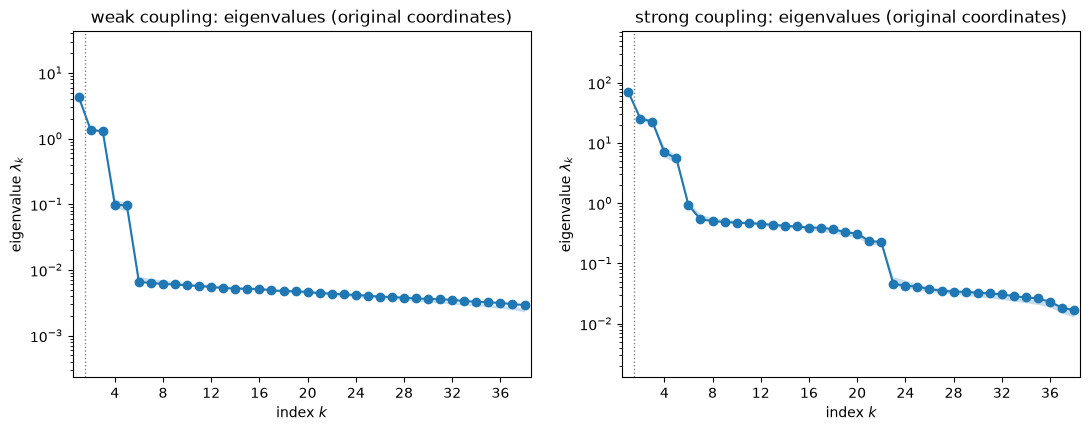

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, c in zip(axes, CASES):
    ac.plotting.plot_eigenvalues(sub[c], ax=ax)
    ax.set_title(f'{c} coupling: eigenvalues (original coordinates)')
plt.close(fig)
fig

In both cases the gap rule picks $n = 1$ ($\lambda_1/\lambda_2 = 3.20$ weak, 2.81 strong), but the clearer gap is after the third eigenvalue: in the weak case $\lambda_2/\lambda_1 = 0.312$ and $\lambda_3/\lambda_1 = 0.301$ are nearly equal and $\lambda_3/\lambda_4 = 13.23$, and the next pair, 0.0227 and 0.0222, is followed by another gap ($\lambda_5/\lambda_6 = 14.67$). Five eigenvalues exceed 1 % of $\lambda_1$ in the weak case and six in the strong case (the sixth is 0.0130), close to the paper's "only the first five eigenvalues are relevant" ([[1]](https://doi.org/10.1017/jfm.2015.730) p. 16–17, Fig. 10). $\lambda_1$ is 16.5 times larger in the strong case; the paper reports about two orders of magnitude, in a normalization it does not state.

weak: bootstrap mean subspace distance, n = 1..6: 0.032, 0.422, 0.024, 0.600, 0.058, 0.776
strong: bootstrap mean subspace distance, n = 1..6: 0.040, 0.227, 0.069, 0.223, 0.059, 0.156


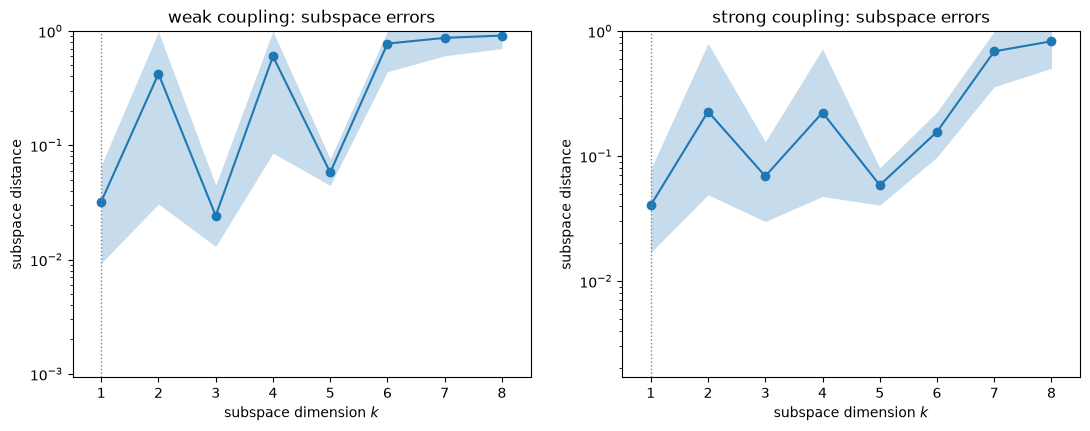

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, c in zip(axes, CASES):
    ac.plotting.plot_subspace_errors(sub[c], ax=ax, k_max=8)
    ax.set_title(f'{c} coupling: subspace errors')
for c in CASES:
    print(f'{c}: bootstrap mean subspace distance, n = 1..6: '
          + ', '.join(f'{v:.3f}' for v in ac.mean_distance(sub[c])[:6]))
plt.close(fig)
fig

The bootstrap subspace distances confirm the eigenvalue pairs: in the weak case the one-dimensional subspace (0.032) and the three-dimensional one (0.024) are well determined, while $n = 2$ (0.422) and $n = 4$ (0.600) split a nearly repeated pair. In the strong case the distances are 0.040 ($n = 1$), 0.069 ($n = 3$) and 0.059 ($n = 5$).

weak: w1 n-part mean +0.012 (sd 0.003), tau-part mean -0.229 (sd 0.003); share of |w_k|^2 on the gains n_i: w1 0.003, w2 0.003, w3 0.004
strong: w1 n-part mean +0.170 (sd 0.010), tau-part mean -0.154 (sd 0.006); share of |w_k|^2 on the gains n_i: w1 0.552, w2 0.422, w3 0.418


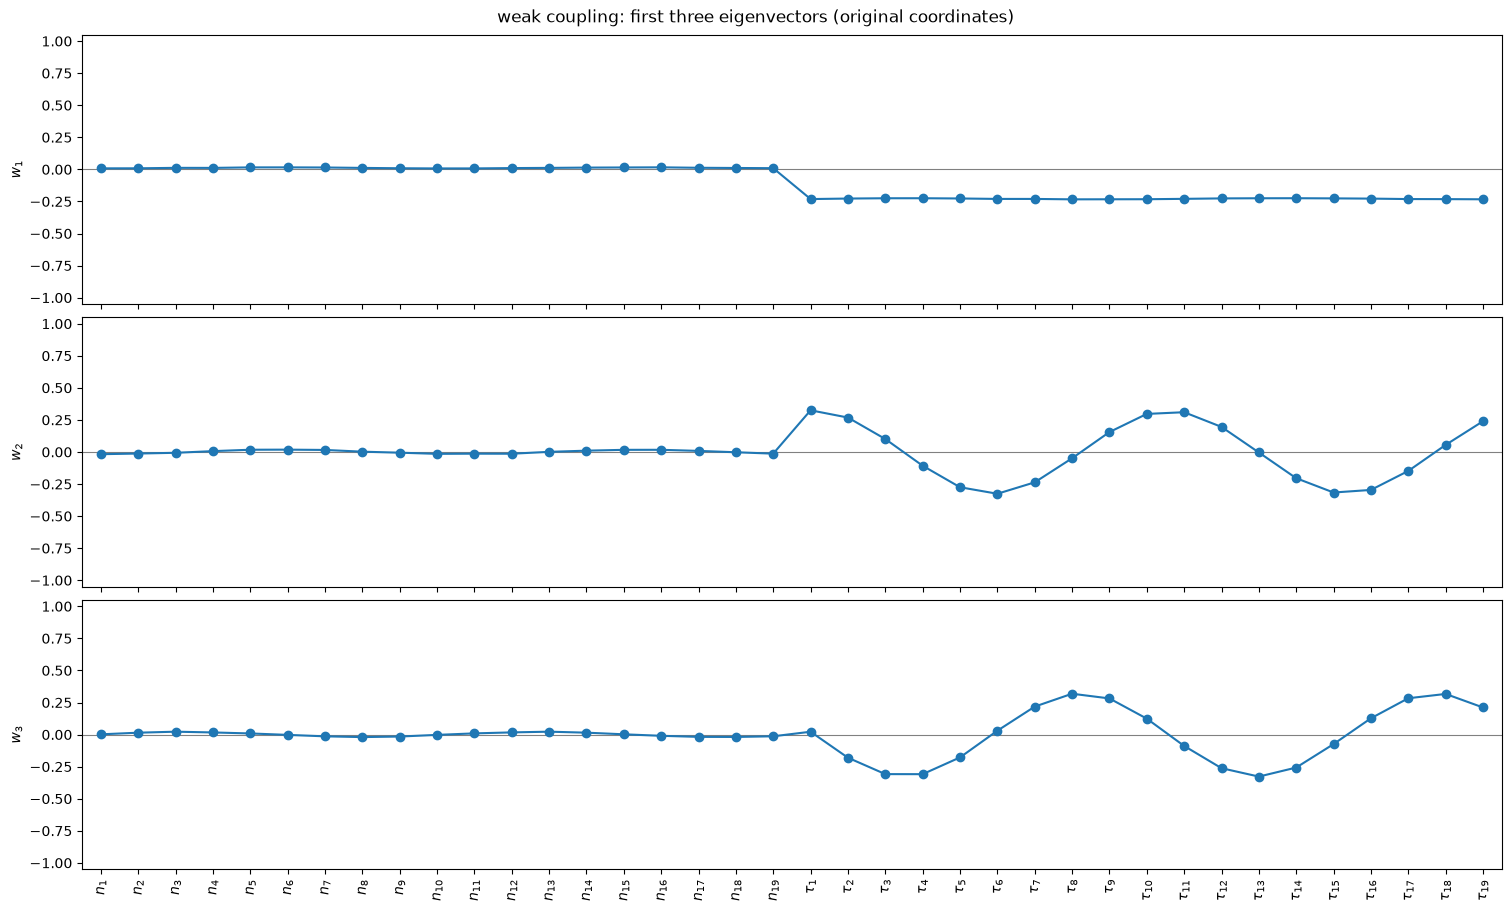

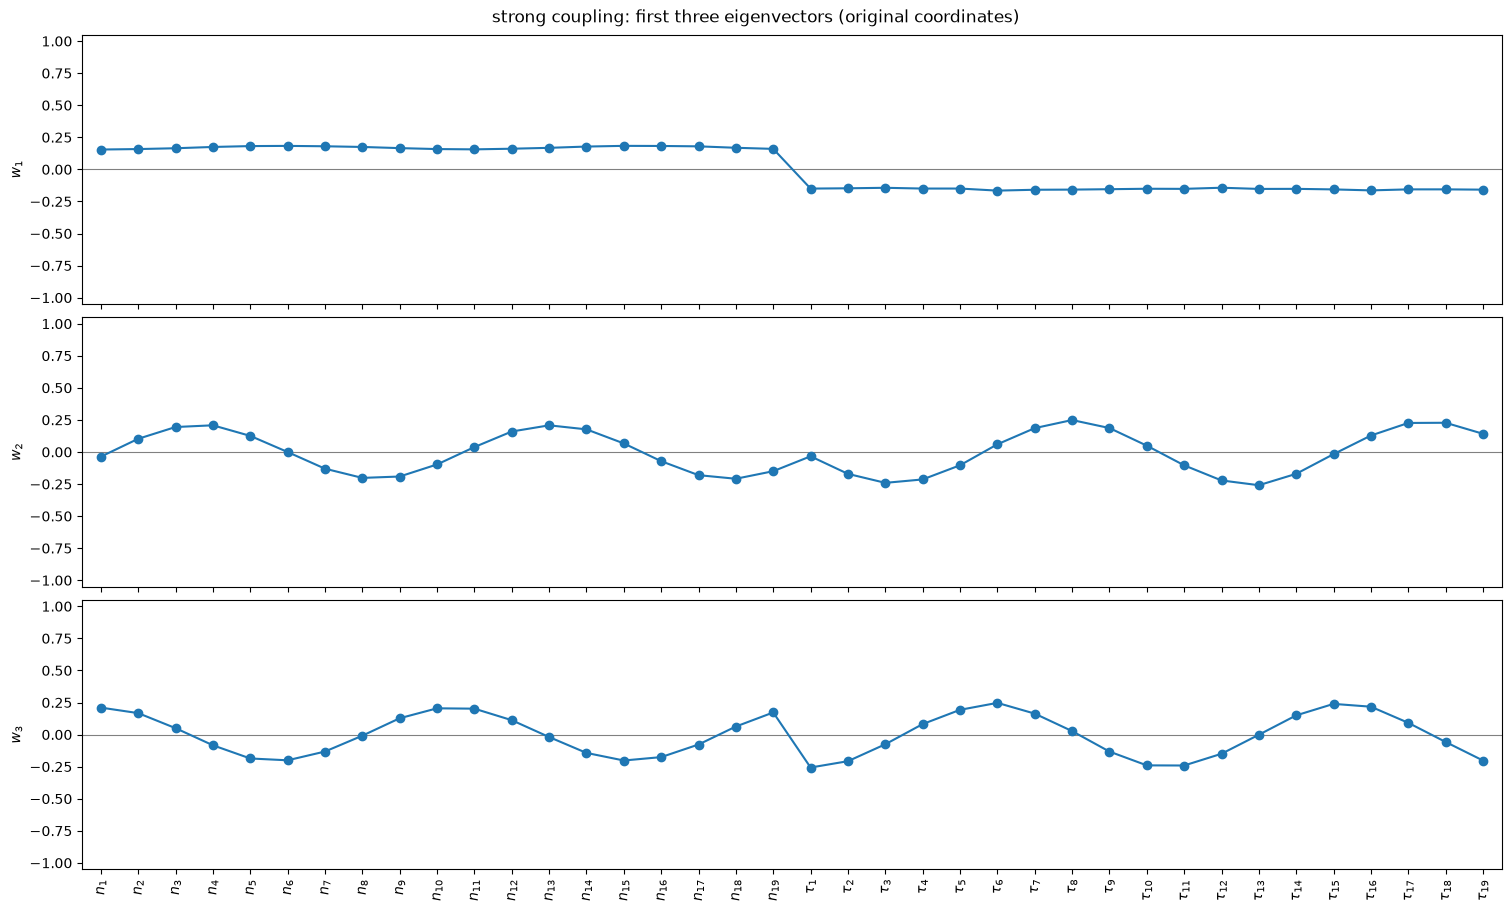

In [8]:
figs = {}
for c in CASES:
    W = sub3[c].W
    print(f'{c}: w1 n-part mean {W[:N, 0].mean():+.3f} (sd {W[:N, 0].std():.3f}), tau-part mean '
          f'{W[N:, 0].mean():+.3f} (sd {W[N:, 0].std():.3f}); share of |w_k|^2 on the gains n_i: '
          + ', '.join(f'w{k + 1} {np.sum(W[:N, k] ** 2):.3f}' for k in range(3)))
    figs[c] = ac.plotting.plot_eigenvectors(sub3[c], indices=[0, 1, 2], labels=labels, figsize=(15, 9))[0]
    figs[c].suptitle(f'{c} coupling: first three eigenvectors (original coordinates)')
plt.close(figs['weak'])
plt.close(figs['strong'])
display(figs['weak'])
figs['strong']

The first eigenvector of the weak case weights the 19 time delays equally (mean component $-0.229$, standard deviation 0.003 across burners) and the gains hardly at all: the gains carry 0.3–0.4 % of $\|\mathbf w_k\|^2$ for $k = 1, 2, 3$, as in [[1]](https://doi.org/10.1017/jfm.2015.730) (p. 17, Fig. 11: "coefficients associated with the FTF amplitude are almost null for Wcase"). In the strong case gains and delays both matter: the gains carry 55 % of $\|\mathbf w_1\|^2$ and about 42 % of $\mathbf w_2$, $\mathbf w_3$ ([[1]](https://doi.org/10.1017/jfm.2015.730) Fig. 12). In both cases $\mathbf w_2$ and $\mathbf w_3$ oscillate twice around the annulus (period $N/2$), the pattern the paper links to the Fourier coefficients $\hat F(\pm 2)$. (Signs: $\mathbf w_1, \mathbf w_2, \mathbf w_3$ are oriented so that $f$ increases with each active variable.)

weak: corr(y1, f) = 0.897
strong: corr(y1, f) = 0.887


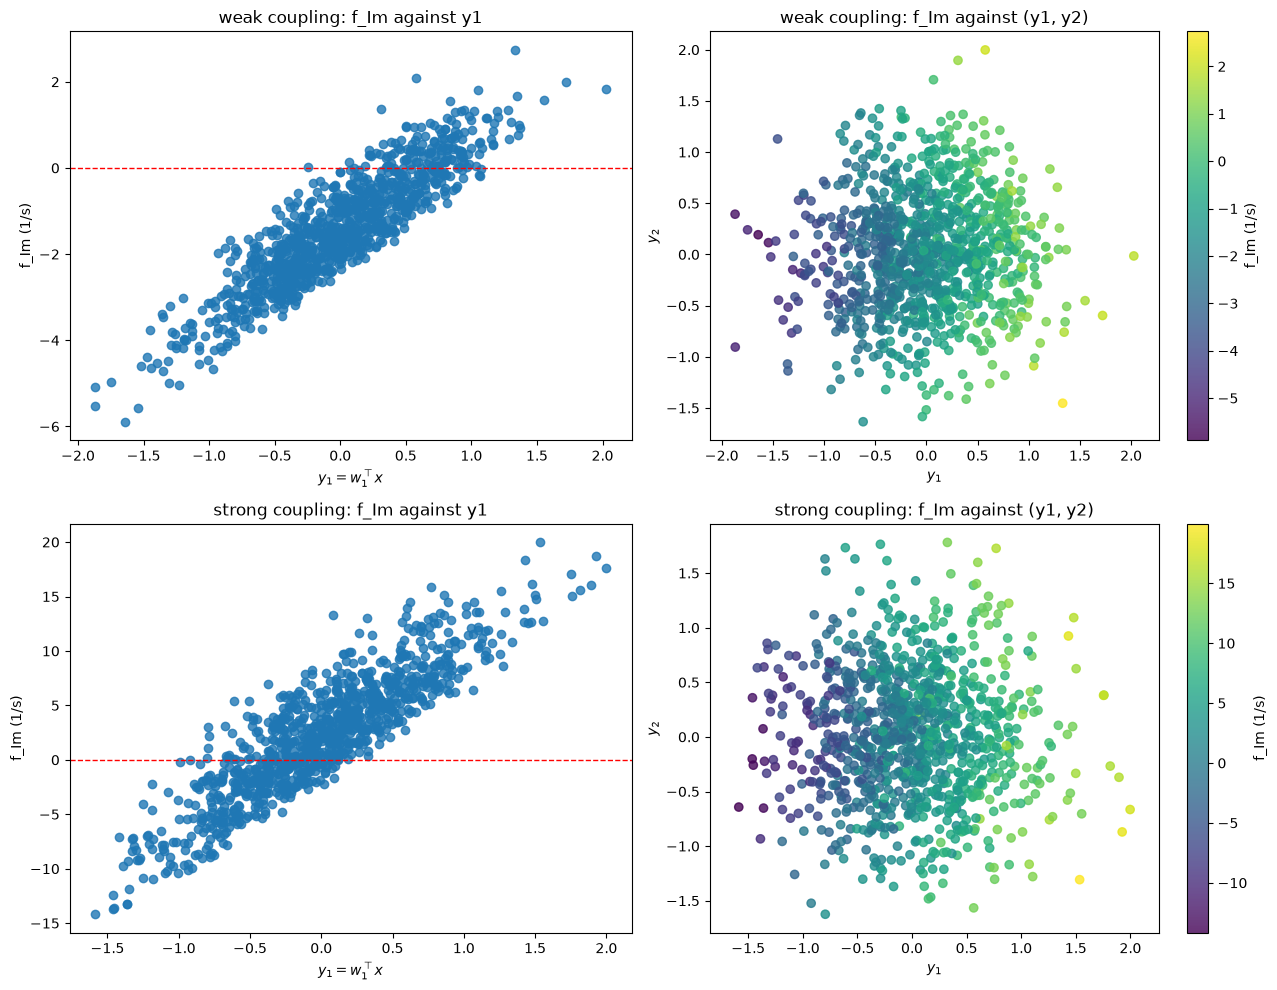

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, c in enumerate(CASES):
    ac.plotting.plot_sufficient_summary(sub3[c], X=D[c]['X'], f=D[c]['f'], dims=1,
                                        qoi_label='f_Im (1/s)', ax=axes[row, 0])
    ac.plotting.plot_sufficient_summary(sub3[c], X=D[c]['X'], f=D[c]['f'], dims=2,
                                        qoi_label='f_Im (1/s)', ax=axes[row, 1])
    axes[row, 0].axhline(0, color='r', ls='--', lw=1)
    axes[row, 0].set_title(f'{c} coupling: f_Im against y1')
    axes[row, 1].set_title(f'{c} coupling: f_Im against (y1, y2)')
    Y = space[c].to_normalized(D[c]['X']) @ sub3[c].W[:, :3]
    print(f"{c}: corr(y1, f) = {np.corrcoef(Y[:, 0], D[c]['f'])[0, 1]:.3f}")
fig.tight_layout()
plt.close(fig)
fig

$f_{Im}$ increases along $y_1$ with $\mathrm{corr}(y_1, f) = 0.897$ (weak) and 0.887 (strong); the spread about the trend is the effect of $y_2$ and $y_3$, the symmetry-breaking directions, which raise the larger growth rate on both sides of zero (the two-dimensional plots). The dashed line is the stability limit $f_{Im} = 0$.

### The physics-guided change of variables

For flames at the burner exit and weak coupling, the analytic theory gives the frequency of the $p$-th azimuthal mode in terms of a coupling strength $\Sigma_0 \propto \hat F(0)$ and a splitting strength $S_0 = \sqrt{\hat\Gamma(2p)\hat\Gamma(-2p)}$, where $\hat F(k) = \sum_{i=1}^{N} F_i e^{-2\pi jki/N}$ is the spatial Fourier transform of $F_i = n_i e^{j\omega^0\tau_i}$, $\omega^0 = \pi c^0/L_c$ ([[1]](https://doi.org/10.1017/jfm.2015.730) eqs. 2.12–2.14 and 4.1–4.2). So [[1]](https://doi.org/10.1017/jfm.2015.730) recomputes the subspace in the coordinates $\{\mathrm{Re}\,\hat F(k), \mathrm{Im}\,\hat F(k)\}_{k=0}^{N-1}$.

With $a_i = n_i\cos\omega^0\tau_i$ and $b_i = n_i\sin\omega^0\tau_i$, the map $(a, b) \mapsto (\mathrm{Re}\,\hat F, \mathrm{Im}\,\hat F)/\sqrt N$ is a real orthogonal $38\times38$ matrix $Q$, so only the polar map $(n_i, \tau_i) \mapsto (a_i, b_i)$ is nonlinear. The chain rule, with $r_i = \sqrt{a_i^2 + b_i^2} = n_i$ and $\omega^0\tau_i = \pi + \mathrm{atan2}(-b_i, -a_i)$ (here $\omega^0\tau_i$ lies between 2.8 and 3.9 rad, so the angle is taken around $\pi$):

$$\frac{\partial f}{\partial a_i} = \frac{\partial f}{\partial n_i}\frac{a_i}{r_i} - \frac{\partial f}{\partial \tau_i}\frac{b_i}{\omega^0 r_i^2},\qquad
\frac{\partial f}{\partial b_i} = \frac{\partial f}{\partial n_i}\frac{b_i}{r_i} + \frac{\partial f}{\partial \tau_i}\frac{a_i}{\omega^0 r_i^2},$$

and $\nabla_{\hat F} f = Q\,\nabla_{(a,b)} f$. (The 2016 notebook used $|a_i|/r_i$ in place of $a_i/r_i$; since $a_i < 0$ in every sample, that flipped the sign of the gain term.) The cell checks the chain rule against central differences of the model through the inverse map. The new coordinates are neither uniform nor independent; all 38 have the same units, so we normalize them with one common scale, the mean sample standard deviation, which keeps $Q$ orthogonal (`ac.Gaussian(mean, cov = s^2 I)` with the sample mean). With per-coordinate scales the eigenvectors would no longer be rotations of each other.

In [10]:
w0 = acm.OMEGA0                                   # pi c0 / L_c, JFM p. 19
th = 2 * np.pi * np.outer(np.arange(1, N + 1), np.arange(N)) / N
Q = np.block([[np.cos(th).T, np.sin(th).T], [-np.sin(th).T, np.cos(th).T]]) / np.sqrt(N)
print(f'omega0 = {w0:.2f} rad/s; Q orthogonal to {np.abs(Q @ Q.T - np.eye(2 * N)).max():.1e}')


def to_fourier(X):
    """[Re F^(0..N-1), Im F^(0..N-1)] / sqrt(N) for F_i = n_i exp(j omega0 tau_i)."""
    n, tau = X[:, :N], X[:, N:]
    return np.c_[n * np.cos(w0 * tau), n * np.sin(w0 * tau)] @ Q.T


def from_fourier(Y):
    ab = Y @ Q
    a, b = ab[:, :N], ab[:, N:]
    return np.c_[np.hypot(a, b), (np.pi + np.arctan2(-b, -a)) / w0]   # w0 tau is near pi


def grad_fourier(X, G):
    """Chain rule: grad of f in the Fourier coordinates from the physical gradient G."""
    n, tau = X[:, :N], X[:, N:]
    a, b = n * np.cos(w0 * tau), n * np.sin(w0 * tau)
    r2 = a ** 2 + b ** 2
    fn, ft = G[:, :N], G[:, N:]
    Ga = fn * a / np.sqrt(r2) - ft * b / (w0 * r2)    # dn/da = a/r,  dtau/da = -b/(w0 r^2)
    Gb = fn * b / np.sqrt(r2) + ft * a / (w0 * r2)    # dn/db = b/r,  dtau/db =  a/(w0 r^2)
    return np.c_[Ga, Gb] @ Q.T


# check the chain rule against central differences through from_fourier (2 samples per case)
for c in CASES:
    X2, G2 = D[c]['X'][:2], D[c]['G'][:2]
    Y2, GY2 = to_fourier(X2), grad_fourier(X2, G2)
    h = 1e-6
    P = np.concatenate([Y2[i] + s * h * np.eye(2 * N) for i in range(2) for s in (1, -1)])
    fP = acm.growth_rate(from_fourier(P), c).reshape(2, 2, 2 * N)
    fd = (fP[:, 0] - fP[:, 1]) / (2 * h)
    print(f'{c}: round trip max |X - from_fourier(to_fourier(X))| / X = '
          f'{np.abs(from_fourier(to_fourier(X2)) / X2 - 1).max():.1e}; chain rule vs central differences: '
          f'relative error {(np.linalg.norm(fd - GY2, axis=1) / np.linalg.norm(GY2, axis=1)).max():.1e}')

subF, YF = {}, {}
for c in CASES:
    Y = to_fourier(D[c]['X'])
    GY = grad_fourier(D[c]['X'], D[c]['G'])
    s_common = Y.std(axis=0).mean()
    spaceF = ac.Gaussian(mean=Y.mean(axis=0), cov=np.full(2 * N, s_common ** 2))
    sF = ac.active_subspace(space=spaceF, X=Y, grads=GY, n=3, nboot=500, rng=SEED)
    subF[c] = ac.orient(sF, by='covariance', X=Y, f=D[c]['f'], columns=3)
    YF[c] = Y
    lam = sF.eigenvalues
    print(f'{c}: common scale {s_common:.4f}; lambda_k/lambda_1, k = 1..7: '
          + ', '.join(f'{v:.4f}' for v in lam[:7] / lam[0])
          + f'; lambda_3/lambda_4 = {lam[2] / lam[3]:.2f}, lambda_5/lambda_6 = {lam[4] / lam[5]:.1f}')
    Wf = sF.eigenvectors
    share = Wf[:N] ** 2 + Wf[N:] ** 2                     # |coefficient|^2 of F^(k), per eigenvector
    print('    share of |w|^2 on F^(0), F^(2), F^(N-2) for w1..w6: '
          + '; '.join(f'w{j + 1}: {share[0, j]:.3f}, {share[2, j]:.3f}, {share[N - 2, j]:.3f}' for j in range(6)))

omega0 = 4840.38 rad/s; Q orthogonal to 2.8e-15


weak: round trip max |X - from_fourier(to_fourier(X))| / X = 3.7e-15; chain rule vs central differences: relative error 2.5e-09


strong: round trip max |X - from_fourier(to_fourier(X))| / X = 3.7e-15; chain rule vs central differences: relative error 9.9e-09


weak: common scale 0.0644; lambda_k/lambda_1, k = 1..7: 1.0000, 0.3105, 0.2999, 0.0515, 0.0500, 0.0001, 0.0000; lambda_3/lambda_4 = 5.82, lambda_5/lambda_6 = 516.7
    share of |w|^2 on F^(0), F^(2), F^(N-2) for w1..w6: w1: 1.000, 0.000, 0.000; w2: 0.000, 0.502, 0.498; w3: 0.000, 0.486, 0.514; w4: 0.000, 0.500, 0.500; w5: 0.000, 0.513, 0.487; w6: 0.996, 0.000, 0.000


strong: common scale 0.2511; lambda_k/lambda_1, k = 1..7: 1.0000, 0.3434, 0.2937, 0.0713, 0.0535, 0.0225, 0.0003; lambda_3/lambda_4 = 4.12, lambda_5/lambda_6 = 2.4
    share of |w|^2 on F^(0), F^(2), F^(N-2) for w1..w6: w1: 0.997, 0.001, 0.002; w2: 0.000, 0.575, 0.424; w3: 0.003, 0.487, 0.509; w4: 0.000, 0.425, 0.574; w5: 0.000, 0.510, 0.490; w6: 0.999, 0.001, 0.000


The chain rule agrees with central differences to $2.5\times10^{-9}$ (weak) and $9.9\times10^{-9}$ (strong). In the Fourier coordinates the weak case has eigenvalues $1, 0.3105, 0.2999, 0.0515, 0.0500$ and then $10^{-4}$: $f_{Im}$ depends, to that precision, on only five of the 38 coordinates, and they are exactly the ones the theory names. $\mathbf w_1$ lies on $\hat F(0)$ (share 1.000), and $\mathbf w_2$ to $\mathbf w_5$ on $\hat F(2)$ and $\hat F(-2) = \hat F(17)$, about half each; the sixth direction is the other component of $\hat F(0)$ (0.996). The strong case is similar (1, 0.3434, 0.2937, 0.0713, 0.0535, 0.0225, then 0.0003), with the same five directions plus a sixth, again on $\hat F(0)$ (0.999). The three leading directions are the paper's ([[1]](https://doi.org/10.1017/jfm.2015.730) Figs. 13–14), but we do not see its reduction "from 5 to only 3": the gap after the third eigenvalue shrinks in the weak case ($\lambda_3/\lambda_4$ = 5.82 against 13.23 in the original coordinates) and grows only a little in the strong case (4.12 against 3.22), because $\hat F(\pm 2)$ are two complex numbers, four real directions, two strong and two weaker. What the change of variables does is to make the dimension exactly 5 (weak) or 6 (strong): the tail drops from 0.0015 to $10^{-4}$ of $\lambda_1$ in the weak case.

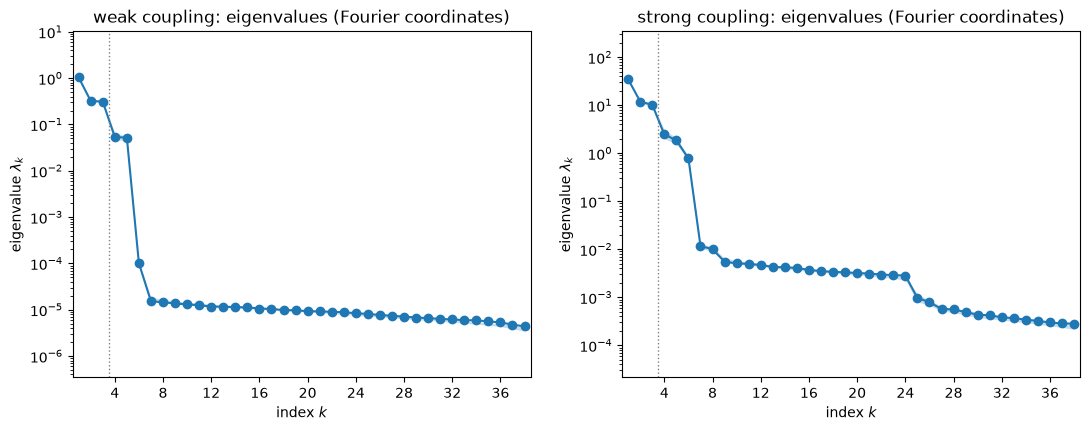

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, c in zip(axes, CASES):
    ac.plotting.plot_eigenvalues(subF[c], ax=ax)
    ax.set_title(f'{c} coupling: eigenvalues (Fourier coordinates)')
plt.close(fig)
fig

For comparison with [[1]](https://doi.org/10.1017/jfm.2015.730) Fig. 14 (weak case, 1000 samples), here are the coefficients of $\mathbf w_1, \mathbf w_2, \mathbf w_3$ on the real and imaginary parts of $\hat F(k)$, $k = 0, \dots, 18$; $k = 17$ is $-2$.

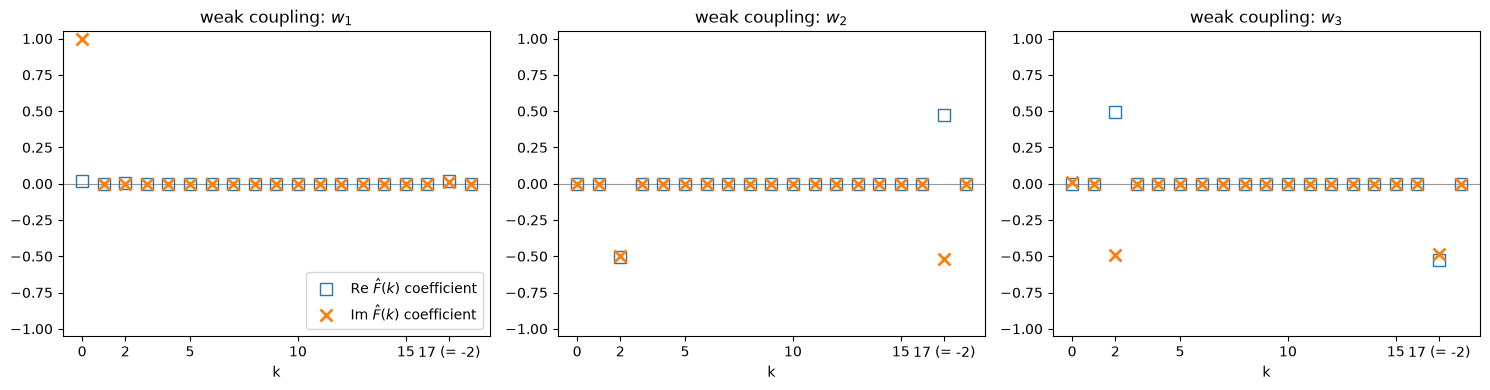

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
W = subF['weak'].W
k = np.arange(N)
for j, ax in enumerate(axes):
    ax.axhline(0, color='0.6', lw=0.8)
    ax.plot(k, W[:N, j], 's', mfc='none', ms=8, label=r'Re $\hat F(k)$ coefficient')
    ax.plot(k, W[N:, j], 'x', ms=8, mew=2, label=r'Im $\hat F(k)$ coefficient')
    ax.set_xticks([0, 2, 5, 10, 15, N - 2])
    ax.set_xticklabels(['0', '2', '5', '10', '15', '17 (= -2)'])
    ax.set_ylim(-1.05, 1.05)
    ax.set_xlabel('k')
    ax.set_title(f'weak coupling: $w_{j + 1}$')
axes[0].legend(loc='lower right')
fig.tight_layout()
plt.close(fig)
fig

$\mathbf w_1$ is the imaginary part of $\hat F(0)$, i.e. the mean of $n_i\sin\omega^0\tau_i$, which (since $\omega^0\bar\tau \approx \pi$) is driven by the mean time delay; $\mathbf w_2$ and $\mathbf w_3$ use only $\hat F(2)$ and $\hat F(-2)$, as in the paper's Fig. 14.

### Surrogates on the active variables

As in [[1]](https://doi.org/10.1017/jfm.2015.730) §4.2 (Table 3), we fit least-squares polynomials: linear in all 38 normalized inputs (FL), and linear, quadratic and cubic in the three active variables (RL, RQ, RC), both in the original and in the Fourier coordinates, on the 1000 samples. We report the leave-one-out $R^2$ and, as in the paper's eq. (4.5), $R = 1 - \mathrm{Var}(\tilde f - f)/\mathrm{Var}(f)$ on the 10 000 Monte Carlo samples (the inputs are redrawn with `gd.mc_inputs`).

In [13]:
def r2(g, f):
    return 1 - np.var(g - f) / np.var(f)          # JFM eq. (4.5)


SUR, RQ = {}, {}
for c in CASES:
    X, f = D[c]['X'], D[c]['f']
    Xmc = gd.mc_inputs(c)                         # the inputs of montecarlo_<c>.csv, from its seed
    fmc = D[c]['mc'][:, 0]
    fits = {'FL (38 inputs, linear)': ac.fit_surrogate(X=X, f=f, space=space[c], subspace=None, kind='poly', degree=1)}
    for deg, nm in ((1, 'L'), (2, 'Q'), (3, 'C')):
        fits[f'R{nm} (3 active, original)'] = ac.fit_surrogate(X=X, f=f, subspace=sub3[c], kind='poly', degree=deg)
    for deg, nm in ((1, 'L'), (2, 'Q'), (3, 'C')):
        fits[f'R{nm} (3 active, Fourier)'] = ac.fit_surrogate(X=YF[c], f=f, subspace=subF[c], kind='poly', degree=deg)
    print(f'{c}: {"surrogate":28s}{"LOO R^2":>9s}{"R, 10 000 MC":>14s}')
    for name, s in fits.items():
        Xv = to_fourier(Xmc) if 'Fourier' in name else Xmc
        print(f'      {name:28s}{s.loo_r_squared:9.3f}{r2(ac.predict(s, Xv), fmc):14.3f}')
    SUR[c] = fits
    RQ[c] = fits['RQ (3 active, Fourier)']

weak: surrogate                     LOO R^2  R, 10 000 MC
      FL (38 inputs, linear)          0.797         0.799
      RL (3 active, original)         0.805         0.804
      RQ (3 active, original)         0.966         0.964
      RC (3 active, original)         0.966         0.963
      RL (3 active, Fourier)          0.813         0.812
      RQ (3 active, Fourier)          0.978         0.975
      RC (3 active, Fourier)          0.978         0.974
strong: surrogate                     LOO R^2  R, 10 000 MC
      FL (38 inputs, linear)          0.782         0.781
      RL (3 active, original)         0.787         0.789
      RQ (3 active, original)         0.931         0.930
      RC (3 active, original)         0.931         0.929
      RL (3 active, Fourier)          0.799         0.804
      RQ (3 active, Fourier)          0.938         0.942
      RC (3 active, Fourier)          0.939         0.941


For the weak case the accuracies match [[1]](https://doi.org/10.1017/jfm.2015.730) Table 4 at $M = 1000$ (FL 0.80, RL 0.80, RQ 0.96, RC 0.96): here FL 0.799, RL 0.804, RQ 0.964 and RC 0.963 on the validation set in the original coordinates. The Fourier coordinates do slightly better (RQ 0.975), and a cubic adds nothing. In the strong case the quadratic reaches 0.930 (original) and 0.942 (Fourier), much better than the paper's 75 % (RQ30) and 63 % (FQ1000) ([[1]](https://doi.org/10.1017/jfm.2015.730) p. 24). That is consistent with the explanation below: the larger of two smooth growth rates is close to a quadratic in the active variables, while a QoI that jumps between the two components is not.

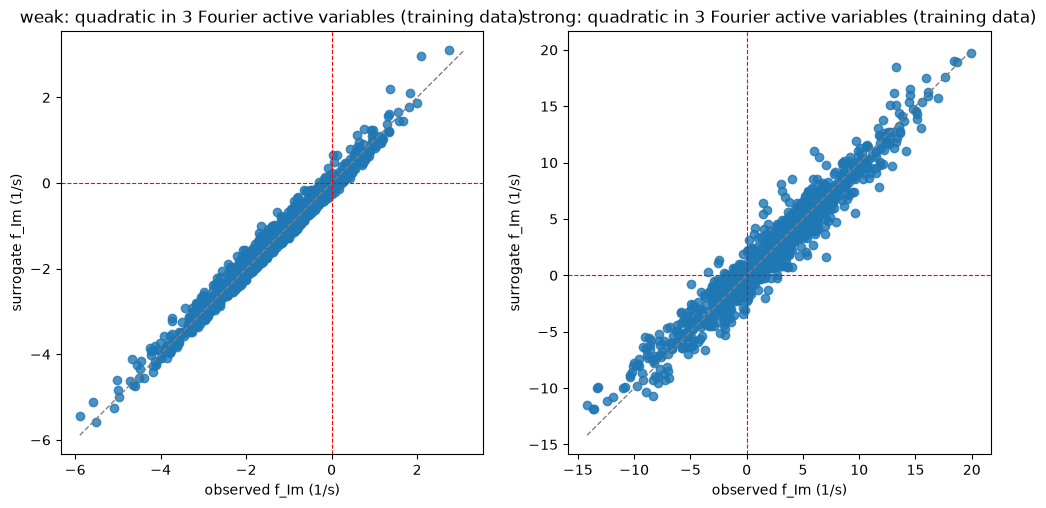

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, c in zip(axes, CASES):
    ac.plotting.plot_surrogate_fit(RQ[c], X=YF[c], f=D[c]['f'], qoi_label='f_Im (1/s)', ax=ax)
    ax.axhline(0, color='r', ls='--', lw=0.8)
    ax.axvline(0, color='r', ls='--', lw=0.8)
    ax.set_title(f'{c}: quadratic in 3 Fourier active variables (training data)')
plt.close(fig)
fig

### Risk factor

The risk factor is $P(f_{Im} > 0)$. We give it three ways per case: the fraction of the 1000 data samples, the fraction of the 10 000 Monte Carlo runs of the model, and the RQ surrogate in Fourier coordinates evaluated at 50 000 fresh samples (`rng=SEED`); and the surrogate risk factors of FL, RL and RQ in the original coordinates beside [[1]](https://doi.org/10.1017/jfm.2015.730) Table 5. For the strong case we also give what a single component would give.

In [15]:
PAPER_RF = {'weak': 14.77, 'strong': 39.55}              # JFM Table 5 and App. A (10 000 ATACAMAC runs)
PAPER_RQ1000 = {'weak': 14.94, 'strong': 39.03}
PAPER_T5 = {'weak': {'FL': 11.90, 'RL': 11.94, 'RQ': 14.94}, 'strong': {'FL': 32.03, 'RL': 33.17, 'RQ': 39.03}}
RF = {}
for c in CASES:
    f, mc = D[c]['f'], D[c]['mc']
    p_mc = (mc[:, 0] > 0).mean()
    Xs = space[c].sample(50000, rng=SEED)
    g = ac.predict(RQ[c], to_fourier(Xs))
    hi = np.where(mc[:, 2] > mc[:, 3], mc[:, 0], mc[:, 1])      # growth rate of the higher-frequency component
    RF[c] = dict(data=100 * (f > 0).mean(), mc=100 * p_mc, se=100 * np.sqrt(p_mc * (1 - p_mc) / len(mc)),
                 sur=100 * (g > 0).mean(), other=100 * (mc[:, 1] > 0).mean(),
                 one=50 * ((mc[:, 0] > 0).mean() + (mc[:, 1] > 0).mean()), hi=100 * (hi > 0).mean(), g=g)
    r = RF[c]
    print(f'{c}: risk factor P(f_Im > 0): data (M = 1000) {r["data"]:.2f} %; Monte Carlo (10 000) '
          f'{r["mc"]:.2f} % +- {r["se"]:.2f}; RQ surrogate on 50 000 fresh samples {r["sur"]:.2f} %; '
          f'paper {PAPER_RF[c]:.2f} % (paper RQ1000 {PAPER_RQ1000[c]:.2f} %)')
    print(f'      one component only (Monte Carlo): other component {r["other"]:.2f} %, a random one of the two '
          f'{r["one"]:.2f} %, the higher-frequency one {r["hi"]:.2f} %')
    print(f'      Monte Carlo f_Im: mean {mc[:, 0].mean():.2f}, sd {mc[:, 0].std():.2f} 1/s; '
          f'both components pooled: mean {mc[:, :2].mean():.2f} 1/s')
    print('      surrogate risk factors on the same 50 000 samples (paper Table 5, M = 1000, in brackets): '
          + ', '.join(f'{nm} {100 * (ac.predict(SUR[c][key], to_fourier(Xs) if "Fourier" in key else Xs) > 0).mean():.2f} % ({PAPER_T5[c][nm]})'
                      for nm, key in (('FL', 'FL (38 inputs, linear)'), ('RL', 'RL (3 active, original)'),
                                      ('RQ', 'RQ (3 active, original)')))
          + f', RQ Fourier {r["sur"]:.2f} %')

weak: risk factor P(f_Im > 0): data (M = 1000) 15.10 %; Monte Carlo (10 000) 15.33 % +- 0.36; RQ surrogate on 50 000 fresh samples 14.84 %; paper 14.77 % (paper RQ1000 14.94 %)
      one component only (Monte Carlo): other component 0.67 %, a random one of the two 8.00 %, the higher-frequency one 7.97 %
      Monte Carlo f_Im: mean -1.41, sd 1.36 1/s; both components pooled: mean -2.39 1/s


      surrogate risk factors on the same 50 000 samples (paper Table 5, M = 1000, in brackets): FL 11.75 % (11.9), RL 11.66 % (11.94), RQ 14.66 % (14.94), RQ Fourier 14.84 %
strong: risk factor P(f_Im > 0): data (M = 1000) 66.60 %; Monte Carlo (10 000) 66.49 % +- 0.47; RQ surrogate on 50 000 fresh samples 66.93 %; paper 39.55 % (paper RQ1000 39.03 %)
      one component only (Monte Carlo): other component 18.60 %, a random one of the two 42.55 %, the higher-frequency one 54.08 %
      Monte Carlo f_Im: mean 2.30, sd 5.49 1/s; both components pooled: mean -1.50 1/s


      surrogate risk factors on the same 50 000 samples (paper Table 5, M = 1000, in brackets): FL 68.13 % (32.03), RL 68.12 % (33.17), RQ 66.61 % (39.03), RQ Fourier 66.93 %


**Weak case: agreement.** The model's Monte Carlo risk factor is 15.33 % ± 0.36 % (one binomial standard error) against the paper's 14.77 % with 10 000 ATACAMAC runs (Table 5, App. A), a difference of 1.6 standard errors of our estimate alone; the paper's own estimate has a similar error. The data fraction is 15.10 % and the RQ surrogate gives 14.84 %. The surrogate risk factors match Table 5 to 0.3 points: FL 11.75 % (paper 11.90 %), RL 11.66 % (11.94 %), RQ 14.66 % (14.94 %). The mean of $f_{Im}$ is $-1.41$ s$^{-1}$ and the pooled mean of both components $-2.39$ s$^{-1}$, against the symmetric value $-2.338$.

**Strong case: disagreement, explained by the choice of component.** The larger growth rate is positive in 66.49 % ± 0.47 % of the Monte Carlo runs (data 66.60 %, RQ surrogate 66.93 %), against the paper's 39.55 %, and the surrogate risk factors are 66.6–68.1 % against the paper's 32.0–39.0 %. The other component alone is unstable in 18.60 % of the runs, and a component chosen at random in 42.55 %. The 2016 data, which `DATA.md` compares with this model sample by sample (they are not shipped), show what happened: at every one of the 488 strong-case samples the 2016 growth rate equals one of our two roots to 0.025 s$^{-1}$, and the 2016 gradient equals that root's gradient (median cosine 0.9996), but it is the larger root at only 152 samples and the smaller at 336. The fraction of 2016 values above zero is 37.91 %, close to the paper's 39.55 %, while the larger root at the same 488 inputs gives 69.47 %. In the weak case the 2016 values are the larger root at all 492 samples. So the paper's strong-case reference most likely reports the component that the Newton solver reached from its starting point, not the maximum that the text describes (§4.2, App. A.1); the 2016 data are consistent with this, and only the authors can confirm it for the 10 000-run reference.

Total run time: 13 s


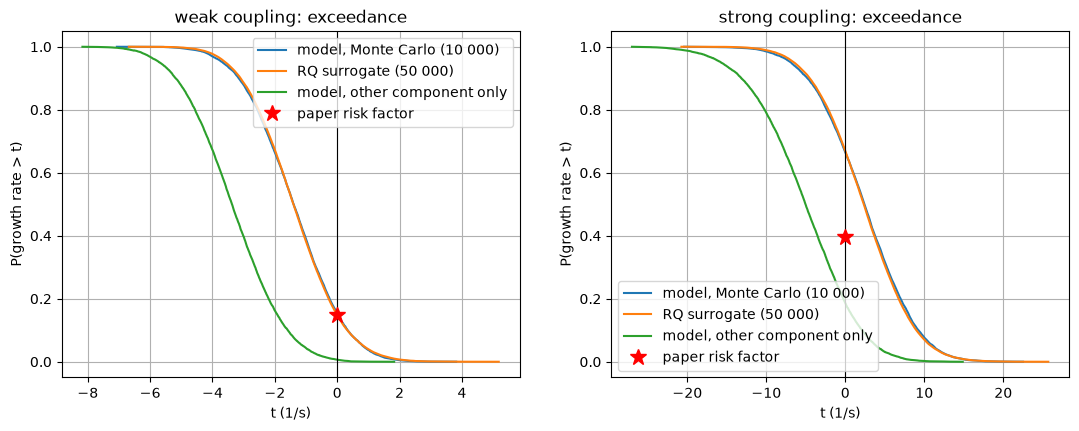

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, c in zip(axes, CASES):
    for v, lab in ((D[c]['mc'][:, 0], 'model, Monte Carlo (10 000)'), (RF[c]['g'], 'RQ surrogate (50 000)'),
                   (D[c]['mc'][:, 1], 'model, other component only')):
        t = np.sort(v)
        ax.plot(t, 1 - np.arange(1, len(t) + 1) / len(t), label=lab)
    ax.axvline(0, color='k', lw=0.8)
    ax.plot([0], [PAPER_RF[c] / 100], 'r*', ms=12, label='paper risk factor')
    ax.set_xlabel('t (1/s)')
    ax.set_ylabel('P(growth rate > t)')
    ax.set_title(f'{c} coupling: exceedance')
    ax.grid(True)
    ax.legend()
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')
plt.close(fig)
fig

The exceedance curves of the model and of the RQ surrogate lie on top of each other in both cases, and the paper's risk factor (star) sits on the model's curve in the weak case. In the strong case it lies between the curve of the larger growth rate and that of the other component, as a mixture of the two would.

### Comparison with the paper

| Quantity | Paper | This notebook |
|---|---|---|
| Symmetric root, case A of [[2]](https://doi.org/10.1016/j.jcp.2016.07.032) (rad/s) | $5.059\times10^3 - 1.392j$ (Table 2) | $5059.2 - 1.397j$ |
| Symmetric root, case B of [[2]](https://doi.org/10.1016/j.jcp.2016.07.032) (rad/s) | $4.272\times10^3 + 3.600\times10^{-3}j$ (Table 2) | $4272.3 + 3.709j$ |
| Eigenvalues above 1 % of $\lambda_1$, original coordinates | 5, both cases (p. 16–17, Fig. 10) | 5 (weak), 6 (strong) |
| $\lambda_1$ strong / weak | about 100 (p. 16, Fig. 10) | 16.5 |
| Gains in $\mathbf w_1$–$\mathbf w_3$, weak case | almost null (p. 17, Fig. 11) | 0.3–0.4 % of $\|\mathbf w\|^2$ |
| $\mathbf w_1$ | equal weights (p. 18) | equal weights on $\tau_i$ (weak), on $n_i$ and $\tau_i$ (strong) |
| $\mathbf w_2$, $\mathbf w_3$ | period $N/2$; $\hat F(\pm 2)$ (pp. 18–19, Figs. 11–14) | period $N/2$; $\hat F(\pm 2)$ |
| Dimension after the change of variables | 3 (p. 19, Fig. 13) | 3 dominant; exactly 5 (weak) or 6 (strong) nonzero |
| $R$, weak, $M = 1000$: FL / RL / RQ / RC | 0.80 / 0.80 / 0.96 / 0.96 (Table 4) | 0.799 / 0.804 / 0.964 / 0.963 |
| $R$, strong: FQ1000 / RQ30 | 0.63 / 0.75 (p. 24) | not computed; RQ (1000) 0.930 |
| Risk factor, weak: Monte Carlo | 14.77 % (Table 5, App. A) | 15.33 % ± 0.36 % |
| Risk factor, weak: FL / RL / RQ, $M = 1000$ | 11.90 / 11.94 / 14.94 % (Table 5) | 11.75 / 11.66 / 14.66 % |
| Risk factor, strong: Monte Carlo | 39.55 % (Table 5, App. A) | 66.49 % ± 0.47 % (larger component); 42.55 % (random component) |
| Risk factor, strong: FL / RL / RQ, $M = 1000$ | 32.03 / 33.17 / 39.03 % (Table 5) | 68.13 / 68.12 / 66.61 % |
| Gradients | finite differences (p. 16) | exact (implicit function theorem), checked to $2\times10^{-9}$ |

### References

[R1]: https://doi.org/10.1017/jfm.2015.730
[R2]: https://doi.org/10.1016/j.jcp.2016.07.032

[1] M. Bauerheim, A. Ndiaye, P. Constantine, S. Moreau and F. Nicoud, Symmetry breaking of azimuthal thermoacoustic modes: the UQ perspective, *J. Fluid Mech.* 789:534–566, 2016. [doi:10.1017/jfm.2015.730](https://doi.org/10.1017/jfm.2015.730). Open copy: HAL hal-01234985 (page and equation numbers in this notebook refer to that manuscript).

[2] L. Magri, M. Bauerheim and M. P. Juniper, Stability analysis of thermo-acoustic nonlinear eigenproblems in annular combustors. Part I. Sensitivity, *J. Comput. Phys.*, 2016. [doi:10.1016/j.jcp.2016.07.032](https://doi.org/10.1016/j.jcp.2016.07.032) (the DOI printed on arXiv:1602.08438v2, which is the version read).

[3] M. Bauerheim, A. Ndiaye, P. Constantine, G. Iaccarino, S. Moreau and F. Nicoud, Uncertainty quantification of thermo-acoustic instabilities in annular combustors, *Proc. Summer Program 2014*, Center for Turbulence Research, Stanford, pp. 209–218 (the companion study with the same UQ setup).

[4] P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

### Acknowledgments

From [[1]](https://doi.org/10.1017/jfm.2015.730): part of the study was performed within the UMRIDA research program (Contract No. FP7-AAT-2013-RTD-1-605036) funded by the European Community, and the authors thank G. Iaccarino and the CTR Summer Program 2014. From [[2]](https://doi.org/10.1016/j.jcp.2016.07.032): L. Magri and M. P. Juniper acknowledge the European Research Council, Project ALORS 2590620, and L. Magri the Royal Academy of Engineering Research Fellowships scheme.